In [ ]:
# Operations

# 0. Preprocess + EDA + Feature Selection
# 1. Extract input and output cols
# 2. Scale the values
# 3. Train test split
# 4. Train the model
# 5. Evaluate the model/model selection
# 6. Deploy the model


In [ ]:
import kagglehub
path = kagglehub.dataset_download("jaikaran109/100-students-placement-dataset")


Using Colab cache for faster access to the '100-students-placement-dataset' dataset.


In [ ]:
import pandas as pd
import numpy as np


In [9]:
import os

print("Files in path:", os.listdir(path))

Files in path: ['placement.csv']


In [11]:
df = pd.read_csv(f"{path}/placement.csv")  # to change the formate from ['placement.csv'] - cell to placement.csv bcz pandas needs .csv

In [15]:
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [16]:
df.shape # the shape of data is 100 by 4

(100, 4)

In [17]:
# Preprocessing

# there is only one unwanted column -> Unnamed
df = df.iloc[:,1:]   # it means i want all rows from st to end but column from 1 to end means here im removing  1st column


In [18]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


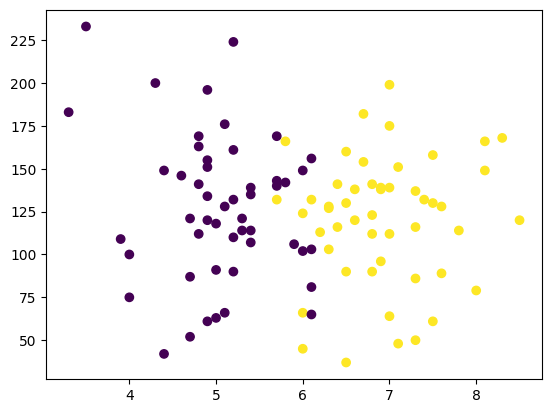

In [19]:
# EDA

import matplotlib.pyplot as plt

plt.scatter(df['cgpa'],df['iq'],c=df['placement'])  # yellow = placed , blue = not placed


# here EDA help us to find the suitable algo like in this case we use logistic regression to separate placed and unplaced its clear by graph which algo we have to use

In [29]:
# 1. Extract input and output cols

X = df.iloc[:,0:2] # sare rows chahiye but column 2 hi chanhiye ----> its independent variable
y = df.iloc[:,-1] # sare rows chahiye but column last one

print(X)
X.shape

print(y)
y.shape

    cgpa     iq
0    6.8  123.0
1    5.9  106.0
2    5.3  121.0
3    7.4  132.0
4    5.8  142.0
..   ...    ...
95   4.3  200.0
96   4.4   42.0
97   6.7  182.0
98   6.3  103.0
99   6.2  113.0

[100 rows x 2 columns]
0     1
1     0
2     0
3     1
4     0
     ..
95    0
96    0
97    1
98    1
99    1
Name: placement, Length: 100, dtype: int64


(100,)

In [38]:
# 3. Train test split

from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.1)  # it seperate the data into 10% random picks into Testing and 90% into Training

print('train indepent dataset \n\n',X_train ,'\n')
print('test indepent dataset \n\n' , X_test,'\n')

print('--------------------------------------------------------------------')
print('train dependent dataset \n\n',y_train,'\n')
print('test dependent dataset \n\n',y_test)

train indepent dataset 

     cgpa     iq
26   7.0  199.0
20   6.6  120.0
61   7.3  137.0
34   4.8  163.0
68   4.0   75.0
..   ...    ...
33   6.0  149.0
18   4.0  100.0
56   6.1   65.0
95   4.3  200.0
47   5.2  161.0

[90 rows x 2 columns] 

test indepent dataset 

     cgpa     iq
54   6.4  141.0
43   6.8  141.0
25   5.0   91.0
32   7.0  139.0
41   5.4  114.0
73   4.9   61.0
78   6.1   81.0
30   7.6  128.0
77   7.3   50.0
90   7.3   86.0 

--------------------------------------------------------------------
train dependent dataset 

 26    1
20    1
61    1
34    0
68    0
     ..
33    0
18    0
56    0
95    0
47    0
Name: placement, Length: 90, dtype: int64 

test dependent dataset 

 54    1
43    1
25    0
32    1
41    0
73    0
78    0
30    1
77    1
90    1
Name: placement, dtype: int64


In [42]:
# 2. Scale the values -- kbhi kbhii data me bahut variation hote h to hm usko -1 to 1 me fit kr dete h

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

print(X_train,'\n\n')  #dekho sari values -1 se 1 ke beech me aa gyi h


X_test = scaler.transform(X_test)
print(X_test)

[[ 0.91536216  1.8357615 ]
 [ 0.56738922 -0.14666017]
 [ 1.17634187  0.2799369 ]
 [-0.99848903  0.93237947]
 [-1.69443492 -1.2758877 ]
 [ 0.13242304  0.75672186]
 [-0.47652962 -0.47288145]
 [-0.99848903 -0.34741173]
 [ 0.0454298  -1.5017332 ]
 [ 0.48039598  0.85709764]
 [ 0.48039598 -0.89947852]
 [-0.47652962  0.33012479]
 [-0.12855667  0.40540662]
 [ 1.0023554   0.63125213]
 [ 1.35032834 -1.62720293]
 [ 1.26333511  0.15446717]
 [-1.78142816 -0.42269356]
 [-0.21554991  1.08294314]
 [-0.99848903  0.38031268]
 [ 0.82836893  0.30503084]
 [ 1.87228776  0.58106424]
 [-0.21554991  0.35521873]
 [-0.21554991  0.15446717]
 [ 0.74137569 -0.07137833]
 [ 0.91536216  1.23350681]
 [-0.73750932  1.25860076]
 [-0.82450256 -1.57701504]
 [-0.99848903  1.08294314]
 [-0.65051609  0.15446717]
 [ 0.48039598 -2.22945761]
 [-0.73750932 -1.5017332 ]
 [-0.47652962  0.22974901]
 [-0.12855667  1.00766131]
 [ 0.0454298  -0.04628439]
 [ 1.35032834  0.10427928]
 [ 2.2202607  -0.14666017]
 [ 0.39340275 -0.24703595]
 

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  warnings.warn(


In [45]:
# 4. Train the model

# -- Logistic Regression Classifier

from sklearn.linear_model import LogisticRegression
clf = LogisticRegression()


# Model Training
clf.fit(X_train,y_train)
print("Model successfully trained:", clf)

Model successfully trained: LogisticRegression()


In [58]:
# 5. Evaluate the model/model selection

# -- isme accuracy nikalte h test data pe


y_pred = clf.predict(X_test)    # ye prediction hai
print(y_test) # ye actual data h

print(y_pred)

54    1
43    1
25    0
32    1
41    0
73    0
78    0
30    1
77    1
90    1
Name: placement, dtype: int64
[0 0 0 0 0 1 1 1 1 1]


In [59]:
# to check the accuracy
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.5

<Axes: >

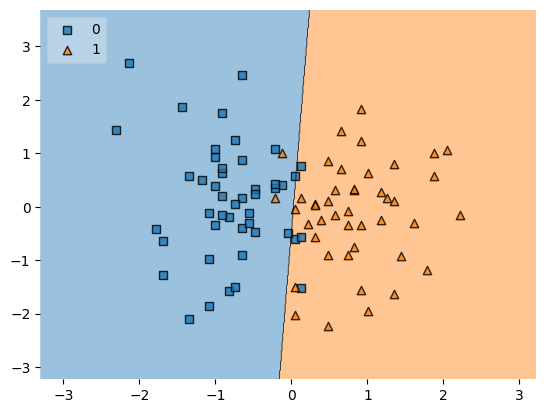

In [62]:

# set the Decision Boundary ---> dekh lo bhai aise  hi partitioon hua tha
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(X_train,y_train.values,clf=clf,legend=2)

In [63]:
import numpy as np

# User se input lena
user_cgpa = float(input("Enter student's CGPA (e.g., 7.5): "))
user_iq = float(input("Enter student's IQ (e.g., 120): "))

# Input ko array me convert karna
new_data = np.array([[user_cgpa, user_iq]])

# Data ko scale karna (jaise training ke waqt kiya tha)
new_data_scaled = scaler.transform(new_data)

# Prediction nikalna
prediction = clf.predict(new_data_scaled)

# Result print karna
if prediction[0] == 1:
    print("\nResult: Yes (Student will be Placed! )")
else:
    print("\nResult: No (Student will not be Placed )")

Enter student's CGPA (e.g., 7.5): 8
Enter student's IQ (e.g., 120): 0

Result: Yes (Student will be Placed! 🎉)
